# FGBuster TNC versus FURAX AdaTopK

This notebook compares two minimisers of the same parametric component-separation likelihood:
the truncated Newton method (TNC) of scipy, as called by FGBuster, and AdaTopK, the box-constrained
minimiser of CADRE used by FURAX. Both fit the same data, with the same patches, start point and
bounds, so any difference comes from the minimiser alone. They are compared, in this order, on the
statistical CMB residual, the systematic CMB residual, the likelihood they reach and the
tensor-to-scalar ratio $r$ inferred from the residuals.

The data are LiteBIRD Q/U maps of the PySM skies `c1d1s1` and `c1d10s5` at $N_{\rm side} = 64$ on
the `ALL-GALACTIC` footprint, with one white-noise realisation (seed 0) at the nominal depth. Each
spectral parameter ($\beta_d$, $T_d$, $\beta_s$) takes one value per patch; the patches are 100
bins of the true PySM value of that parameter. A second fit of each minimiser to the noise-free
foreground maps, with $N = 1$, gives the systematic residual. All settings are in
`tnc_vs_adatopk/common.py`.

| Setting | FGBuster TNC (CPU) | FURAX + CADRE AdaTopK (GPU) |
| --- | --- | --- |
| Code | `fgbuster.adaptive_comp_sep`, `method="TNC"` | `cadre.minimize`, `solver_name="ADABK0"` |
| Algorithm | truncated Newton (scipy) | projected AdaBelief steps, release of one bound constraint at a time (Top-K), projected Armijo line search |
| Objective | $-2\ln\mathcal{L}$ (fgbuster) | $-2\ln\mathcal{L}$ (furax), analytical gradient; $(A^T N^{-1} A)^{-1}$ by `furax.linalg.BlockDiagonalSolver` |
| Start | $\beta_d = 1.54$, $T_d = 20$ K, $\beta_s = -3$ in every patch | same |
| Bounds | $\beta_d \in [0.5, 3]$, $T_d \in [10, 40]$ K, $\beta_s \in [-7, -0.5]$ | same |
| Stopping | `tol = gtol = ftol = xtol = 1e-18`, `maxfun = 20000` (as `fgbuster-model`) | KKT residual below `atol + rtol` times its start value, `atol = rtol = 1e-18`, cooldown 50, at most 10000 iterations |
| Precision | float64 | float64, deterministic GPU reductions |

The fits run in this notebook: about 8 minutes per TNC fit on the CPU and about one minute per
AdaTopK fit on the GPU. The notebook needs furax with `furax.linalg.BlockDiagonalSolver`, CADRE
with `cadre.AdaTopK`, and fgbuster.

## Sky, patches and data

`prepare_sky` builds the frequency maps of each sky (cached in `tnc_vs_adatopk/work`), the
foreground-only maps, the input CMB and the true spectral parameters, all restricted to the
observed pixels. `noisy_data` draws the noise realisation and returns the noisy maps with their
noise covariance; both minimisers receive these same arrays.

In [ ]:
import sys
import time
from pathlib import Path

import healpy as hp
import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, str(Path("tnc_vs_adatopk").resolve()))
import common as cm  # imported before any jax computation: it sets the GPU flags
import jax
from furax_cs.r_analysis.residuals import compute_statistical_res, compute_systematic_res

# furax_cs.r_analysis applies its paper style on import (LaTeX text, large fonts).
plt.rcdefaults()

SKIES = ("c1d1s1", "c1d10s5")
SEED = 0
METHODS = ("TNC", "AdaTopK")
COLORS = {"TNC": "#2a78d6", "AdaTopK": "#eb6834"}
LABEL = {"beta_dust": r"$\beta_d$", "temp_dust": r"$T_d$ [K]", "beta_pl": r"$\beta_s$"}

cm.use_work_dir()
print(cm.hardware(), "| jax", jax.__version__)

skies, patches, data = {}, {}, {}
for tag in SKIES:
    skies[tag] = cm.prepare_sky(tag)
    patches[tag] = cm.ideal_patches(skies[tag])
    data[tag] = cm.noisy_data(skies[tag], SEED)
    print(
        f"{tag}: {skies[tag]['indices'].size} observed pixels "
        f"(f_sky = {skies[tag]['fsky']:.3f}), patches {cm.patch_counts(patches[tag])}"
    )


def masked(tag, values):
    # Values on the observed pixels to a full-sky map, UNSEEN outside the mask.
    m = np.full(cm.NPIX, hp.UNSEEN)
    m[skies[tag]["indices"]] = values
    return m

{'host': '5a564c93d938', 'n_cpu': '12', 'jax_backend': 'gpu', 'jax_device': 'NVIDIA L4'} | jax 0.11.1
[INFO] Loaded freq_maps for nside 64 from cache.
[INFO] Loaded freq_maps for nside 64 from cache.
[INFO] Loaded freq_maps for nside 64 from cache.


c1d1s1: 29009 observed pixels (f_sky = 0.590), patches {'beta_dust': 72, 'temp_dust': 85, 'beta_pl': 100}
[INFO] Loaded freq_maps for nside 64 from cache.
[INFO] Loaded freq_maps for nside 64 from cache.
[INFO] Loaded freq_maps for nside 64 from cache.
c1d10s5: 29009 observed pixels (f_sky = 0.590), patches {'beta_dust': 93, 'temp_dust': 83, 'beta_pl': 93}


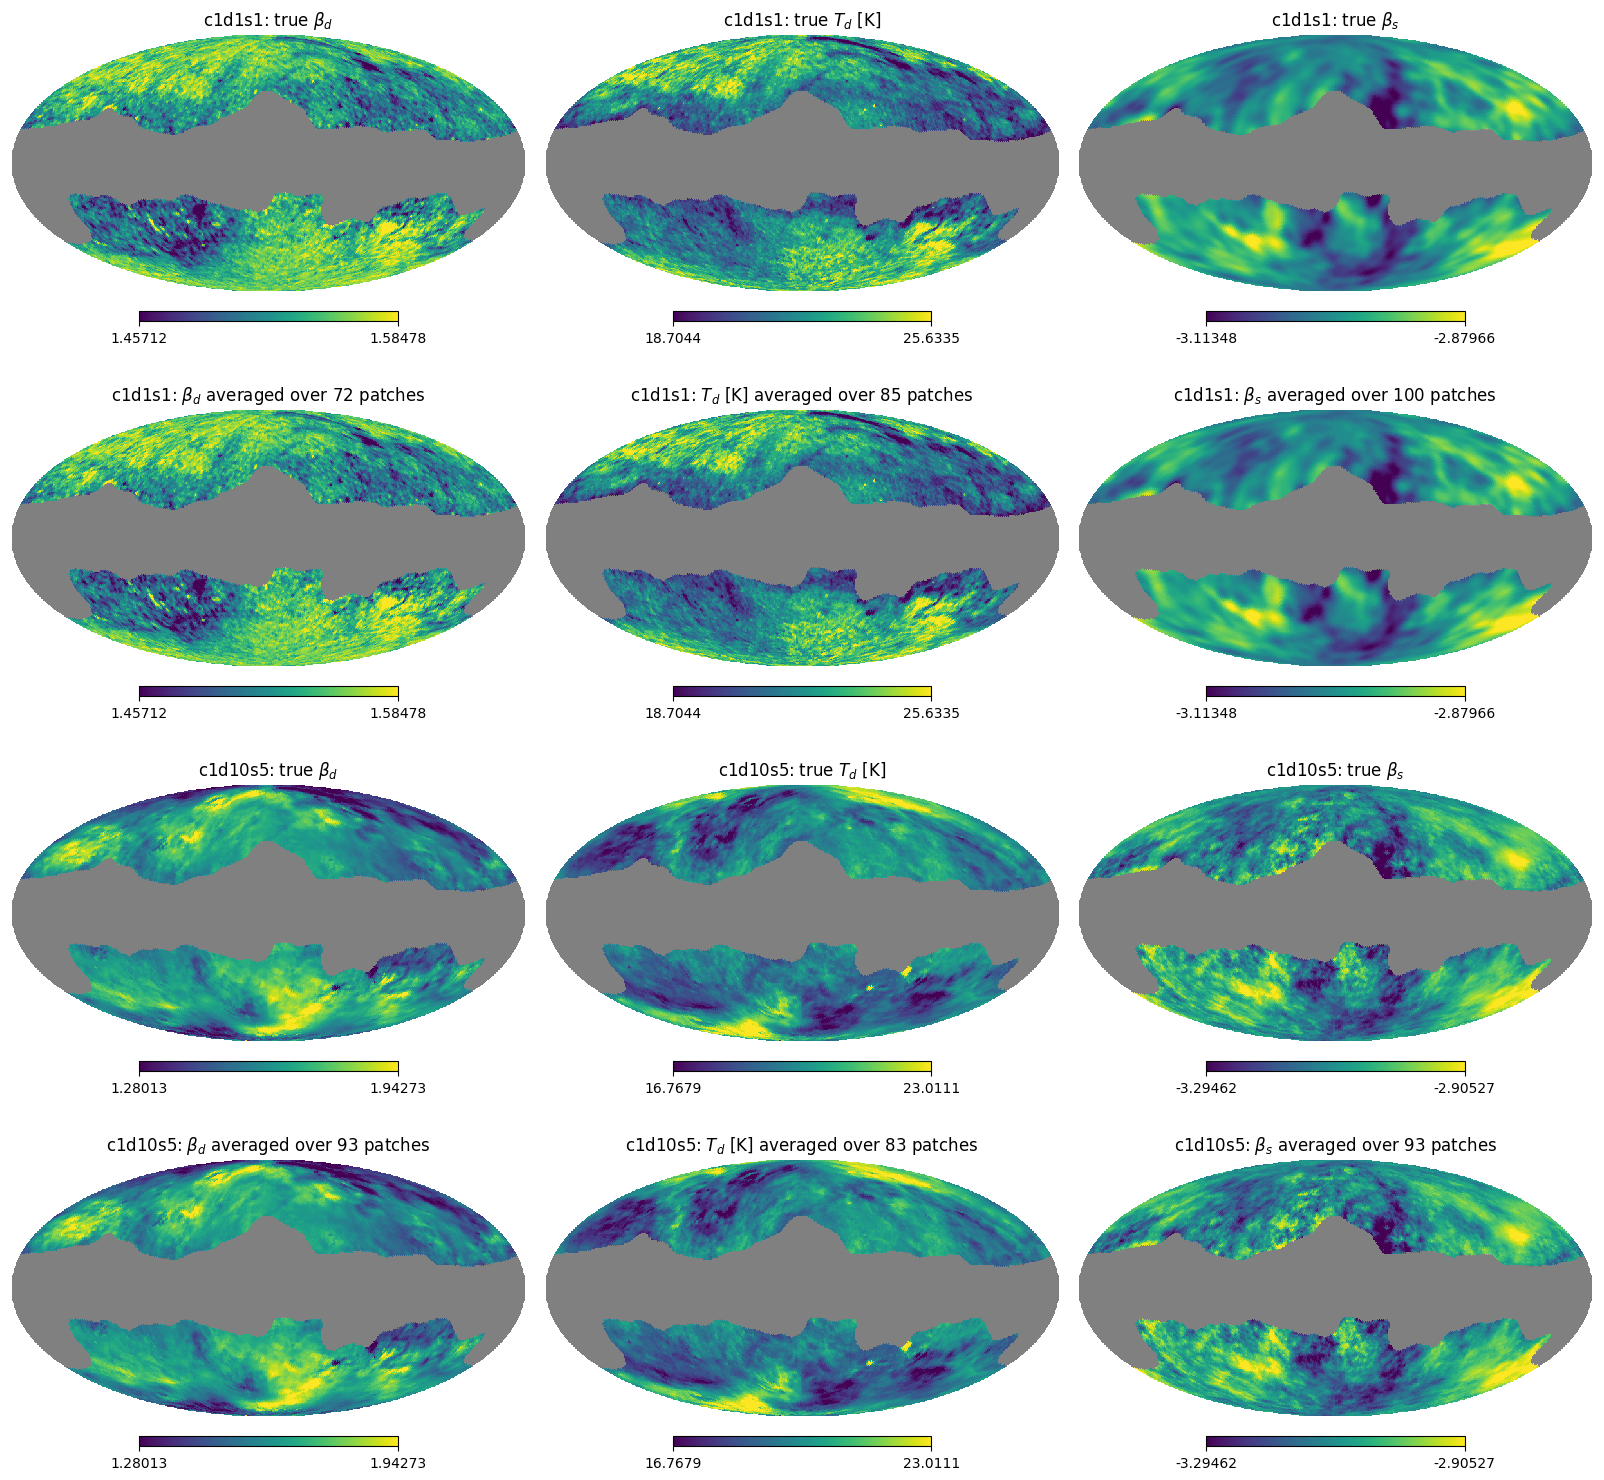

In [ ]:
# Each patch is one bin of the true parameter, so a patch is scattered over the sky. The lower
# map of each pair shows the true parameter averaged over its patch: the best a fit with these
# patches can recover.
fig = plt.figure(figsize=(16, 15))
for k, tag in enumerate(SKIES):
    sky = skies[tag]
    for j, p in enumerate(cm.PARAMS):
        truth = sky["true"][p][sky["indices"]]
        labels = patches[tag][p]
        patch_mean = np.bincount(labels, weights=truth) / np.bincount(labels)
        lo, hi = np.percentile(truth, [1, 99])
        hp.mollview(
            masked(tag, truth),
            sub=(4, 3, 6 * k + j + 1),
            fig=fig.number,
            title=f"{tag}: true {LABEL[p]}",
            min=lo,
            max=hi,
            cmap="viridis",
            notext=True,
        )
        hp.mollview(
            masked(tag, patch_mean[labels]),
            sub=(4, 3, 6 * k + j + 4),
            fig=fig.number,
            title=f"{tag}: {LABEL[p]} averaged over {labels.max() + 1} patches",
            min=lo,
            max=hi,
            cmap="viridis",
            notext=True,
        )
plt.subplots_adjust(hspace=0.35)
plt.show()

## The fits

Each minimiser fits the noisy data (statistical residual, likelihood) and the noise-free
foreground maps with $N = 1$ (systematic residual). TNC runs through `fgbuster.adaptive_comp_sep`
on the CPU. AdaTopK runs through `cadre.minimize` on the GPU; its compilation time is reported
separately from the fit time.

In [ ]:
tnc, tnc_syst = {}, {}
for tag in SKIES:
    tnc[tag] = cm.run_tnc(skies[tag], patches[tag], [SEED])
    t0 = time.perf_counter()
    tnc_syst[tag] = cm.run_tnc_syst(skies[tag], patches[tag])
    print(f"{tag}: TNC noise-free fit {time.perf_counter() - t0:.1f} s", flush=True)

TNC seed 0: 415.0 s, nit=35, nfev=379, status=1 (Converged (|f_n-f_(n-1)| ~= 0))


c1d1s1: TNC noise-free fit 450.2 s


TNC seed 0: 483.9 s, nit=40, nfev=441, status=1 (Converged (|f_n-f_(n-1)| ~= 0))


c1d10s5: TNC noise-free fit 503.6 s


In [ ]:
ada, ada_syst = {}, {}
for tag in SKIES:
    ada[tag] = cm.run_adatopk(skies[tag], patches[tag], [SEED])
    t0 = time.perf_counter()
    ada_syst[tag] = cm.run_adatopk_syst(skies[tag], patches[tag])
    print(
        f"{tag}: AdaTopK compiled in {ada[tag]['compile_time']:.1f} s; noisy fit "
        f"{ada[tag]['time'][0]:.1f} s, {ada[tag]['iters'][0]} iterations; noise-free fit "
        f"(with its compilation) {time.perf_counter() - t0:.1f} s",
        flush=True,
    )

runs = {tag: {"TNC": tnc[tag], "AdaTopK": ada[tag]} for tag in SKIES}
systs = {tag: {"TNC": tnc_syst[tag], "AdaTopK": ada_syst[tag]} for tag in SKIES}
for tag in SKIES:
    print(
        f"{tag}: TNC {tnc[tag]['time'][0]:.0f} s, AdaTopK {ada[tag]['time'][0]:.1f} s, "
        f"ratio {tnc[tag]['time'][0] / ada[tag]['time'][0]:.0f}"
    )

c1d1s1: AdaTopK compiled in 3.5 s; noisy fit 36.8 s, 5646 iterations; noise-free fit (with its compilation) 31.0 s


c1d10s5: AdaTopK compiled in 3.4 s; noisy fit 38.7 s, 6048 iterations; noise-free fit (with its compilation) 35.1 s


c1d1s1: TNC 415 s, AdaTopK 36.8 s, ratio 11
c1d10s5: TNC 484 s, AdaTopK 38.7 s, ratio 12


## CMB residuals

The CMB estimate is $\hat{s} = (W d)_{\rm CMB}$ with $W = (A^T N^{-1} A)^{-1} A^T N^{-1}$ at the
fitted parameters. The systematic residual is $(W d_{\rm fg})_{\rm CMB}$ at the parameters of the
noise-free fit, and the statistical residual is $\hat{s} - s_{\rm true}$ minus the systematic
residual. The figure shows their $BB$ spectra (`anafast` on the masked map divided by
$f_{\rm sky}$, through `compute_statistical_res` and `compute_systematic_res` of
`furax_cs.r_analysis`) for $2 \le \ell \le 2 N_{\rm side} + 1$, and the ratio AdaTopK / TNC.

In [ ]:
ell = np.arange(2, 2 * cm.NSIDE + 2)
evals, spectra = {}, {}
for tag in SKIES:
    sky = skies[tag]
    s_true_qu = cm._full_sky_qu(sky, sky["cmb"])
    s_true = np.stack([np.zeros(cm.NPIX), np.asarray(s_true_qu.q), np.asarray(s_true_qu.u)])
    evals[tag], spectra[tag] = {}, {}
    for m in METHODS:
        evals[tag][m] = cm.evaluate_runs(sky, patches[tag], runs[tag][m], [SEED])
        cmb_hat = evals[tag][m]["cmb"]
        wd = cm.syst_cmb(sky, patches[tag], systs[tag][m])
        cl_syst, syst_map = compute_systematic_res(cm._full_sky_qu(sky, wd), sky["fsky"], ell)
        cl_stat, _ = compute_statistical_res(
            cm._full_sky_qu(sky, cmb_hat), s_true, sky["fsky"], ell, syst_map
        )
        spectra[tag][m] = {"cmb_hat": cmb_hat, "wd": wd, "cl_stat": cl_stat, "cl_syst": cl_syst}
    for kind in ("cl_stat", "cl_syst"):
        ratio = spectra[tag]["AdaTopK"][kind] / spectra[tag]["TNC"][kind]
        print(f"{tag} {kind}: AdaTopK / TNC from {ratio.min():.6f} to {ratio.max():.6f} over ell")

[INFO] Realization 0: min BB=3.15e-07, max BB=1.14e-06
Kept 1 out of 1 realizations after filtering.


[INFO] Realization 0: min BB=3.15e-07, max BB=1.14e-06
Kept 1 out of 1 realizations after filtering.
c1d1s1 cl_stat: AdaTopK / TNC from 0.999704 to 1.000251 over ell
c1d1s1 cl_syst: AdaTopK / TNC from 0.998109 to 1.005884 over ell


[INFO] Realization 0: min BB=2.69e-07, max BB=9.11e-07
Kept 1 out of 1 realizations after filtering.


[INFO] Realization 0: min BB=2.69e-07, max BB=9.11e-07
Kept 1 out of 1 realizations after filtering.
c1d10s5 cl_stat: AdaTopK / TNC from 0.998512 to 1.000511 over ell
c1d10s5 cl_syst: AdaTopK / TNC from 0.998118 to 1.003789 over ell


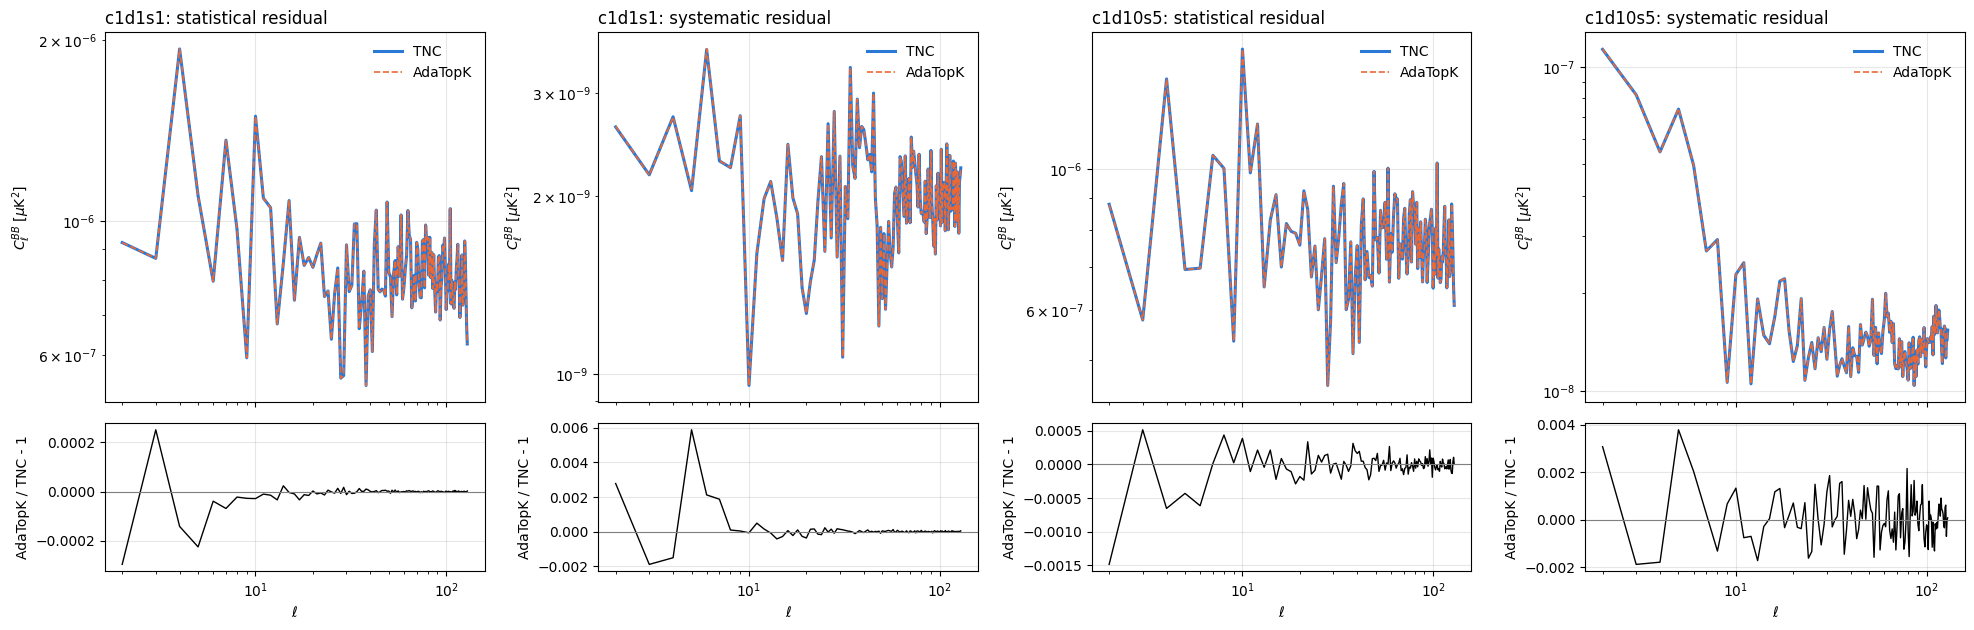

In [ ]:
fig, axes = plt.subplots(
    2,
    4,
    figsize=(24, 7),
    sharex="col",
    gridspec_kw={"height_ratios": [3, 1.2], "hspace": 0.08, "wspace": 0.3},
)
for c, tag in enumerate(SKIES):
    for k, (kind, name) in enumerate((("cl_stat", "statistical"), ("cl_syst", "systematic"))):
        ax, bx = axes[0, 2 * c + k], axes[1, 2 * c + k]
        t, a = spectra[tag]["TNC"][kind], spectra[tag]["AdaTopK"][kind]
        ax.loglog(ell, t, color=COLORS["TNC"], lw=2.2, label="TNC")
        ax.loglog(ell, a, color=COLORS["AdaTopK"], lw=1.2, ls="--", label="AdaTopK")
        bx.semilogx(ell, a / t - 1, color="k", lw=1)
        bx.axhline(0, color="gray", lw=0.8)
        ax.set_title(f"{tag}: {name} residual", loc="left")
        ax.set_ylabel(r"$C_\ell^{BB}$ [$\mu$K$^2$]")
        ax.legend(frameon=False)
        bx.set_xlabel(r"$\ell$")
        bx.set_ylabel("AdaTopK / TNC - 1")
        for x in (ax, bx):
            x.grid(alpha=0.3)
plt.show()

## Likelihood validation

Three checks on the likelihood itself, at the start point and at the two solutions.

1. **Same likelihood.** The furax $-2\ln\mathcal{L}$ and FGBuster's objective are evaluated at
   the same three points. If the two codes implement the same likelihood, their difference is
   the same at every point, up to the rounding of the two full sums, which are of order $10^9$.
2. **Which point is lower.** $-2\ln\mathcal{L}$ is about $10^9$, so its float64 value is resolved
   only to about $10^{-7}$, and summing it accumulates larger rounding errors. The differences
   between points are therefore summed as per-pixel differences (`make_pixel_terms`), which
   resolves them well below $10^{-7}$. The gaps are given
   relative to the TNC solution; a negative value means a lower $-2\ln\mathcal{L}$ than TNC.
3. **How stationary each point is.** The KKT residual is the norm of the projected gradient of
   $-2\ln\mathcal{L}$: a parameter at a bound keeps only the gradient component that points out of
   the box. It is computed with both codes' gradients, together with the number of parameters
   at a bound.

In [ ]:
points, gap_rows = {}, []
for tag in SKIES:
    sky, pt = skies[tag], patches[tag]
    d, N = data[tag]
    init, _, _ = cm.initial_and_bounds(cm.patch_counts(pt))
    points[tag] = {
        "start": {p: np.asarray(init[p]) for p in cm.PARAMS},
        "TNC": {p: runs[tag]["TNC"][p][0] for p in cm.PARAMS},
        "AdaTopK": {p: runs[tag]["AdaTopK"][p][0] for p in cm.PARAMS},
    }
    terms = cm.make_pixel_terms(sky, pt)
    fgbuster_objective = cm.make_fgbuster_objective(sky, pt, d)
    t_tnc = terms(points[tag]["TNC"], d, N)
    print(f"== {tag}")
    print(
        "  point   | -2lnL furax        | -2lnL fgbuster     | furax - fgbuster | gap vs TNC  "
        "| KKT furax | KKT fgbuster | at bound"
    )
    for name, x in points[tag].items():
        ev = cm.evaluate_runs(sky, pt, {p: x[p][None] for p in cm.PARAMS}, [SEED])
        value_fg, grad_fg = fgbuster_objective(x)
        kkt_fg = cm.projected_gradient(x, grad_fg)
        gap = -float(np.sum(terms(x, d, N) - t_tnc))
        n_bound = int(ev["n_at_lower"][0] + ev["n_at_upper"][0])
        print(
            f"  {name:7s} | {float(ev['nll'][0]):.10e} | {value_fg:.10e} | "
            f"{float(ev['nll'][0]) - value_fg:+.6e}    | {gap:+.4e} | {float(ev['pg_norm'][0]):.3e} "
            f"| {kkt_fg['pg_norm']:.3e}    | {n_bound}"
        )
    d_fg = sky["d_fg"]
    n_one = cm.identity_noise(d_fg)
    syst_gap = -float(
        np.sum(terms(systs[tag]["AdaTopK"], d_fg, n_one) - terms(systs[tag]["TNC"], d_fg, n_one))
    )
    print(f"  noise-free fits: AdaTopK - TNC = {syst_gap:+.4e} in -2lnL")

== c1d1s1
  point   | -2lnL furax        | -2lnL fgbuster     | furax - fgbuster | gap vs TNC  | KKT furax | KKT fgbuster | at bound


  start   | -1.0071085475e+09 | -1.0071085820e+09 | +3.449524e+01    | +2.9052e+04 | 1.497e+05 | 1.497e+05    | 0


  TNC     | -1.0071375994e+09 | -1.0071376339e+09 | +3.449546e+01    | -0.0000e+00 | 3.689e-01 | 3.689e-01    | 4


  AdaTopK | -1.0071375994e+09 | -1.0071376339e+09 | +3.449546e+01    | -1.6912e-07 | 4.749e-02 | 4.754e-02    | 4


  noise-free fits: AdaTopK - TNC = +5.9798e-09 in -2lnL


== c1d10s5
  point   | -2lnL furax        | -2lnL fgbuster     | furax - fgbuster | gap vs TNC  | KKT furax | KKT fgbuster | at bound


  start   | -1.0546925268e+09 | -1.0546925638e+09 | +3.692153e+01    | +1.9849e+05 | 6.896e+05 | 6.896e+05    | 0


  TNC     | -1.0548910214e+09 | -1.0548910583e+09 | +3.692230e+01    | -0.0000e+00 | 1.438e-01 | 1.438e-01    | 5


  AdaTopK | -1.0548910214e+09 | -1.0548910583e+09 | +3.692230e+01    | -4.0732e-07 | 2.039e-01 | 2.039e-01    | 5


  noise-free fits: AdaTopK - TNC = -1.7769e-05 in -2lnL


The figure follows $-2\ln\mathcal{L}$ along the straight line through the two solutions,
$x(t) = x_{\rm TNC} + t\,(x_{\rm AdaTopK} - x_{\rm TNC})$, projected on the bounds, relative to the
TNC solution ($t = 0$); AdaTopK is at $t = 1$. A minimum between or near the two points means they
sit in the same valley.

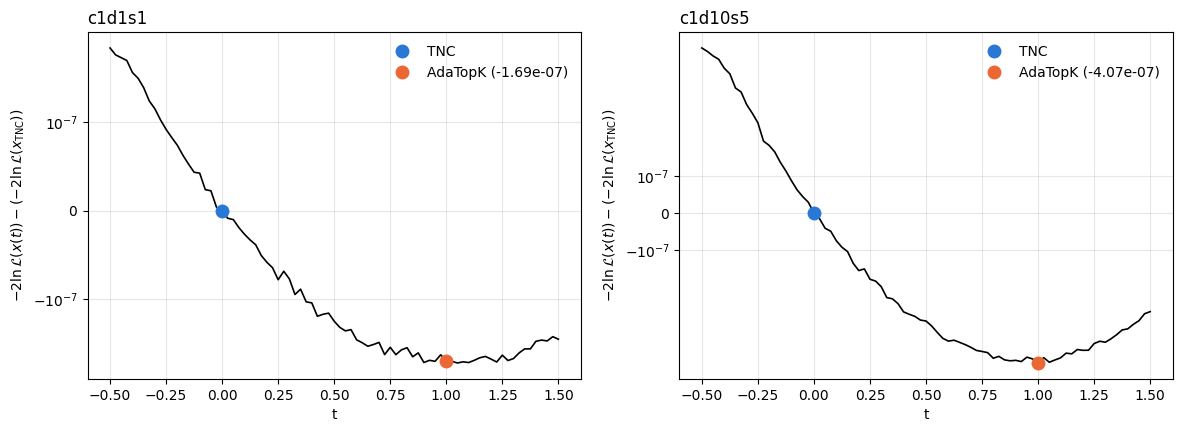

In [ ]:
ts = np.linspace(-0.5, 1.5, 81)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, tag in zip(axes, SKIES):
    sky, pt = skies[tag], patches[tag]
    d, N = data[tag]
    terms = cm.make_pixel_terms(sky, pt)
    x_tnc, x_ada = points[tag]["TNC"], points[tag]["AdaTopK"]
    t_tnc = terms(x_tnc, d, N)
    profile = []
    for t in ts:
        x = {
            p: np.clip(x_tnc[p] + t * (x_ada[p] - x_tnc[p]), cm.LOWER[p], cm.UPPER[p])
            for p in cm.PARAMS
        }
        profile.append(-float(np.sum(terms(x, d, N) - t_tnc)))
    profile = np.asarray(profile)
    gap = profile[np.argmin(np.abs(ts - 1))]
    ax.plot(ts, profile, color="k", lw=1.2)
    ax.plot([0], [0], "o", color=COLORS["TNC"], ms=9, label="TNC")
    ax.plot([1], [gap], "o", color=COLORS["AdaTopK"], ms=9, label=f"AdaTopK ({gap:+.2e})")
    ax.set_yscale("symlog", linthresh=max(abs(gap), 1e-9))
    ax.set_xlabel("t")
    ax.set_ylabel(r"$-2\ln\mathcal{L}(x(t)) - (-2\ln\mathcal{L}(x_{\rm TNC}))$")
    ax.set_title(tag, loc="left")
    ax.legend(frameon=False)
    ax.grid(alpha=0.3)
plt.show()

## Parameter maps

For each parameter, one row for the noise-free fit and one for the noisy fit: the true map, the
TNC and AdaTopK solutions on the same colour scale, and their difference. The difference colour
scale is symmetric, set per row at the 99th percentile of $|{\rm AdaTopK} - {\rm TNC}|$ over the
pixels; larger differences saturate, and the title gives the maximum.

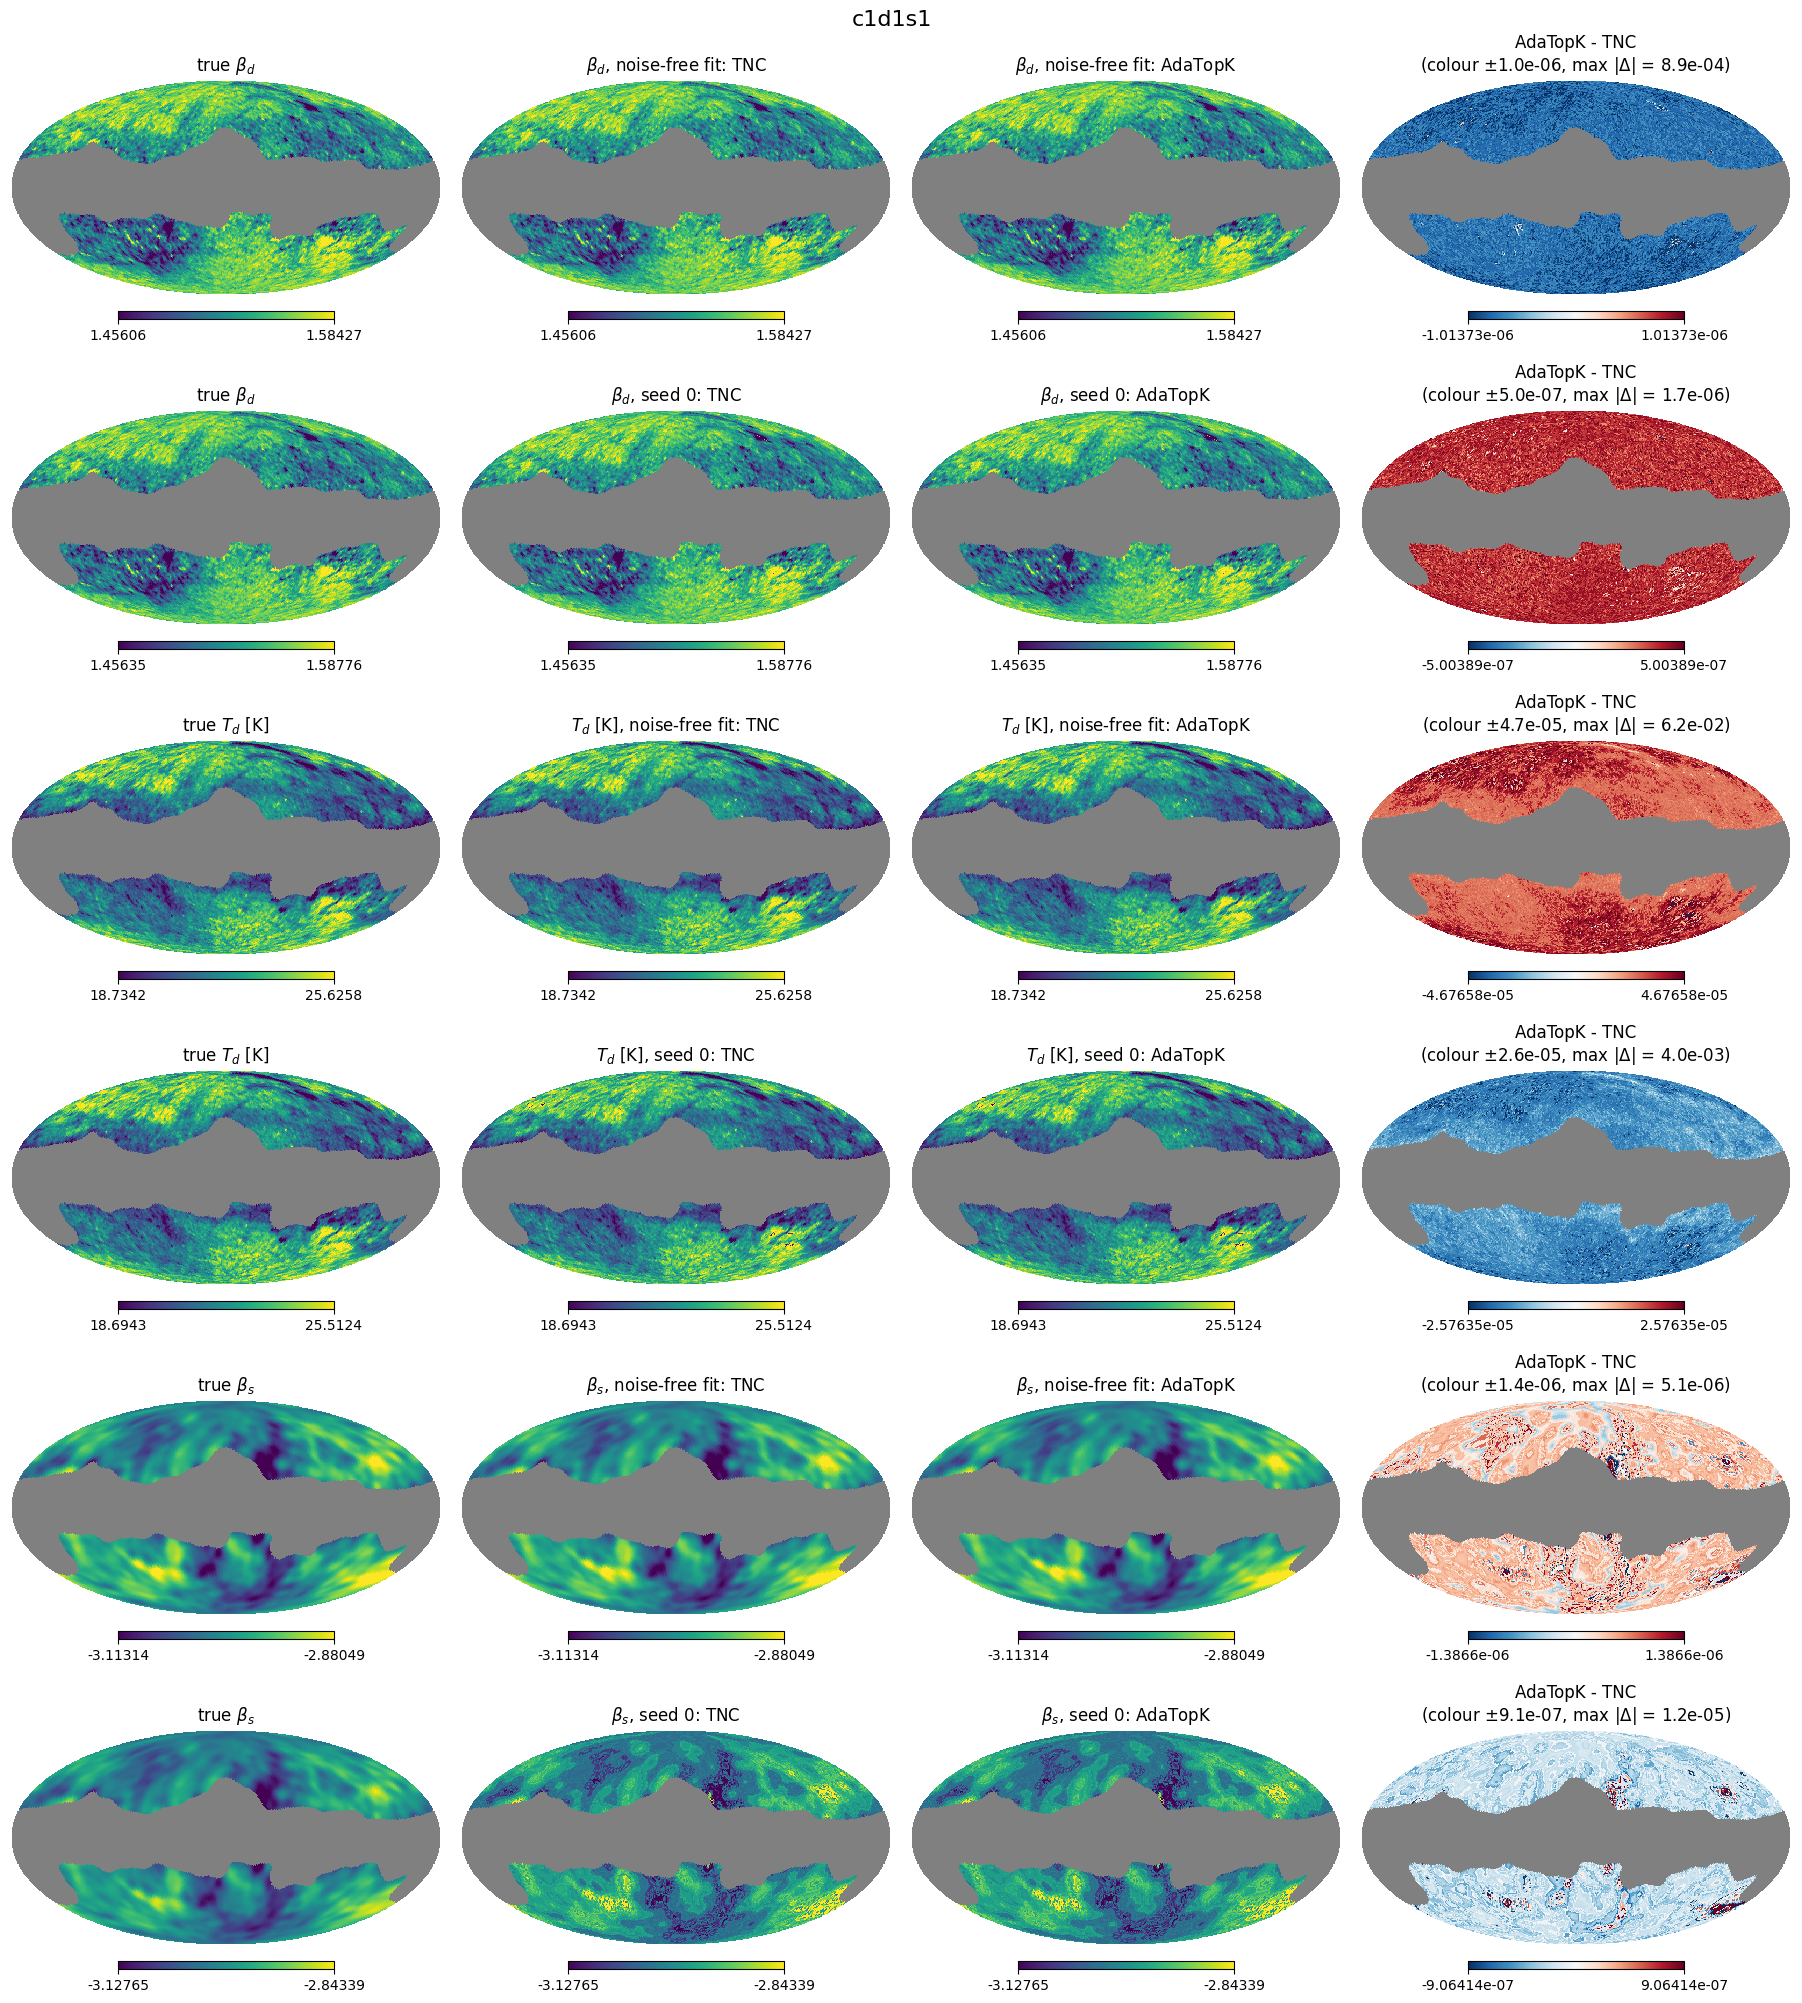

In [ ]:
def plot_parameter_maps(tag):
    sky, pt = skies[tag], patches[tag]
    rows = []
    for p in cm.PARAMS:
        rows.append((p, "noise-free fit", systs[tag]["TNC"][p], systs[tag]["AdaTopK"][p]))
        rows.append((p, f"seed {SEED}", runs[tag]["TNC"][p][0], runs[tag]["AdaTopK"][p][0]))
    fig = plt.figure(figsize=(18, 3.3 * len(rows)))
    for k, (p, label, t, a) in enumerate(rows):
        true_p = sky["true"][p][sky["indices"]]
        t_pix = np.asarray(t)[pt[p]]
        a_pix = np.asarray(a)[pt[p]]
        vmin, vmax = np.percentile(np.concatenate([true_p, t_pix, a_pix]), [1, 99])
        diff = a_pix - t_pix
        dmax = float(np.max(np.abs(diff)))
        d99 = max(float(np.percentile(np.abs(diff), 99)), 1e-15)
        panels = [
            (true_p, f"true {LABEL[p]}", vmin, vmax, "viridis"),
            (t_pix, f"{LABEL[p]}, {label}: TNC", vmin, vmax, "viridis"),
            (a_pix, f"{LABEL[p]}, {label}: AdaTopK", vmin, vmax, "viridis"),
            (
                diff,
                f"AdaTopK - TNC\n(colour $\\pm${d99:.1e}, max $|\\Delta|$ = {dmax:.1e})",
                -d99,
                d99,
                "RdBu_r",
            ),
        ]
        for j, (v, title, lo, hi, cmap) in enumerate(panels):
            hp.mollview(
                masked(tag, v),
                sub=(len(rows), 4, 4 * k + j + 1),
                fig=fig.number,
                title=title,
                min=lo,
                max=hi,
                cmap=cmap,
                notext=True,
            )
    fig.suptitle(tag, y=1.0, fontsize=16)
    plt.show()


plot_parameter_maps("c1d1s1")

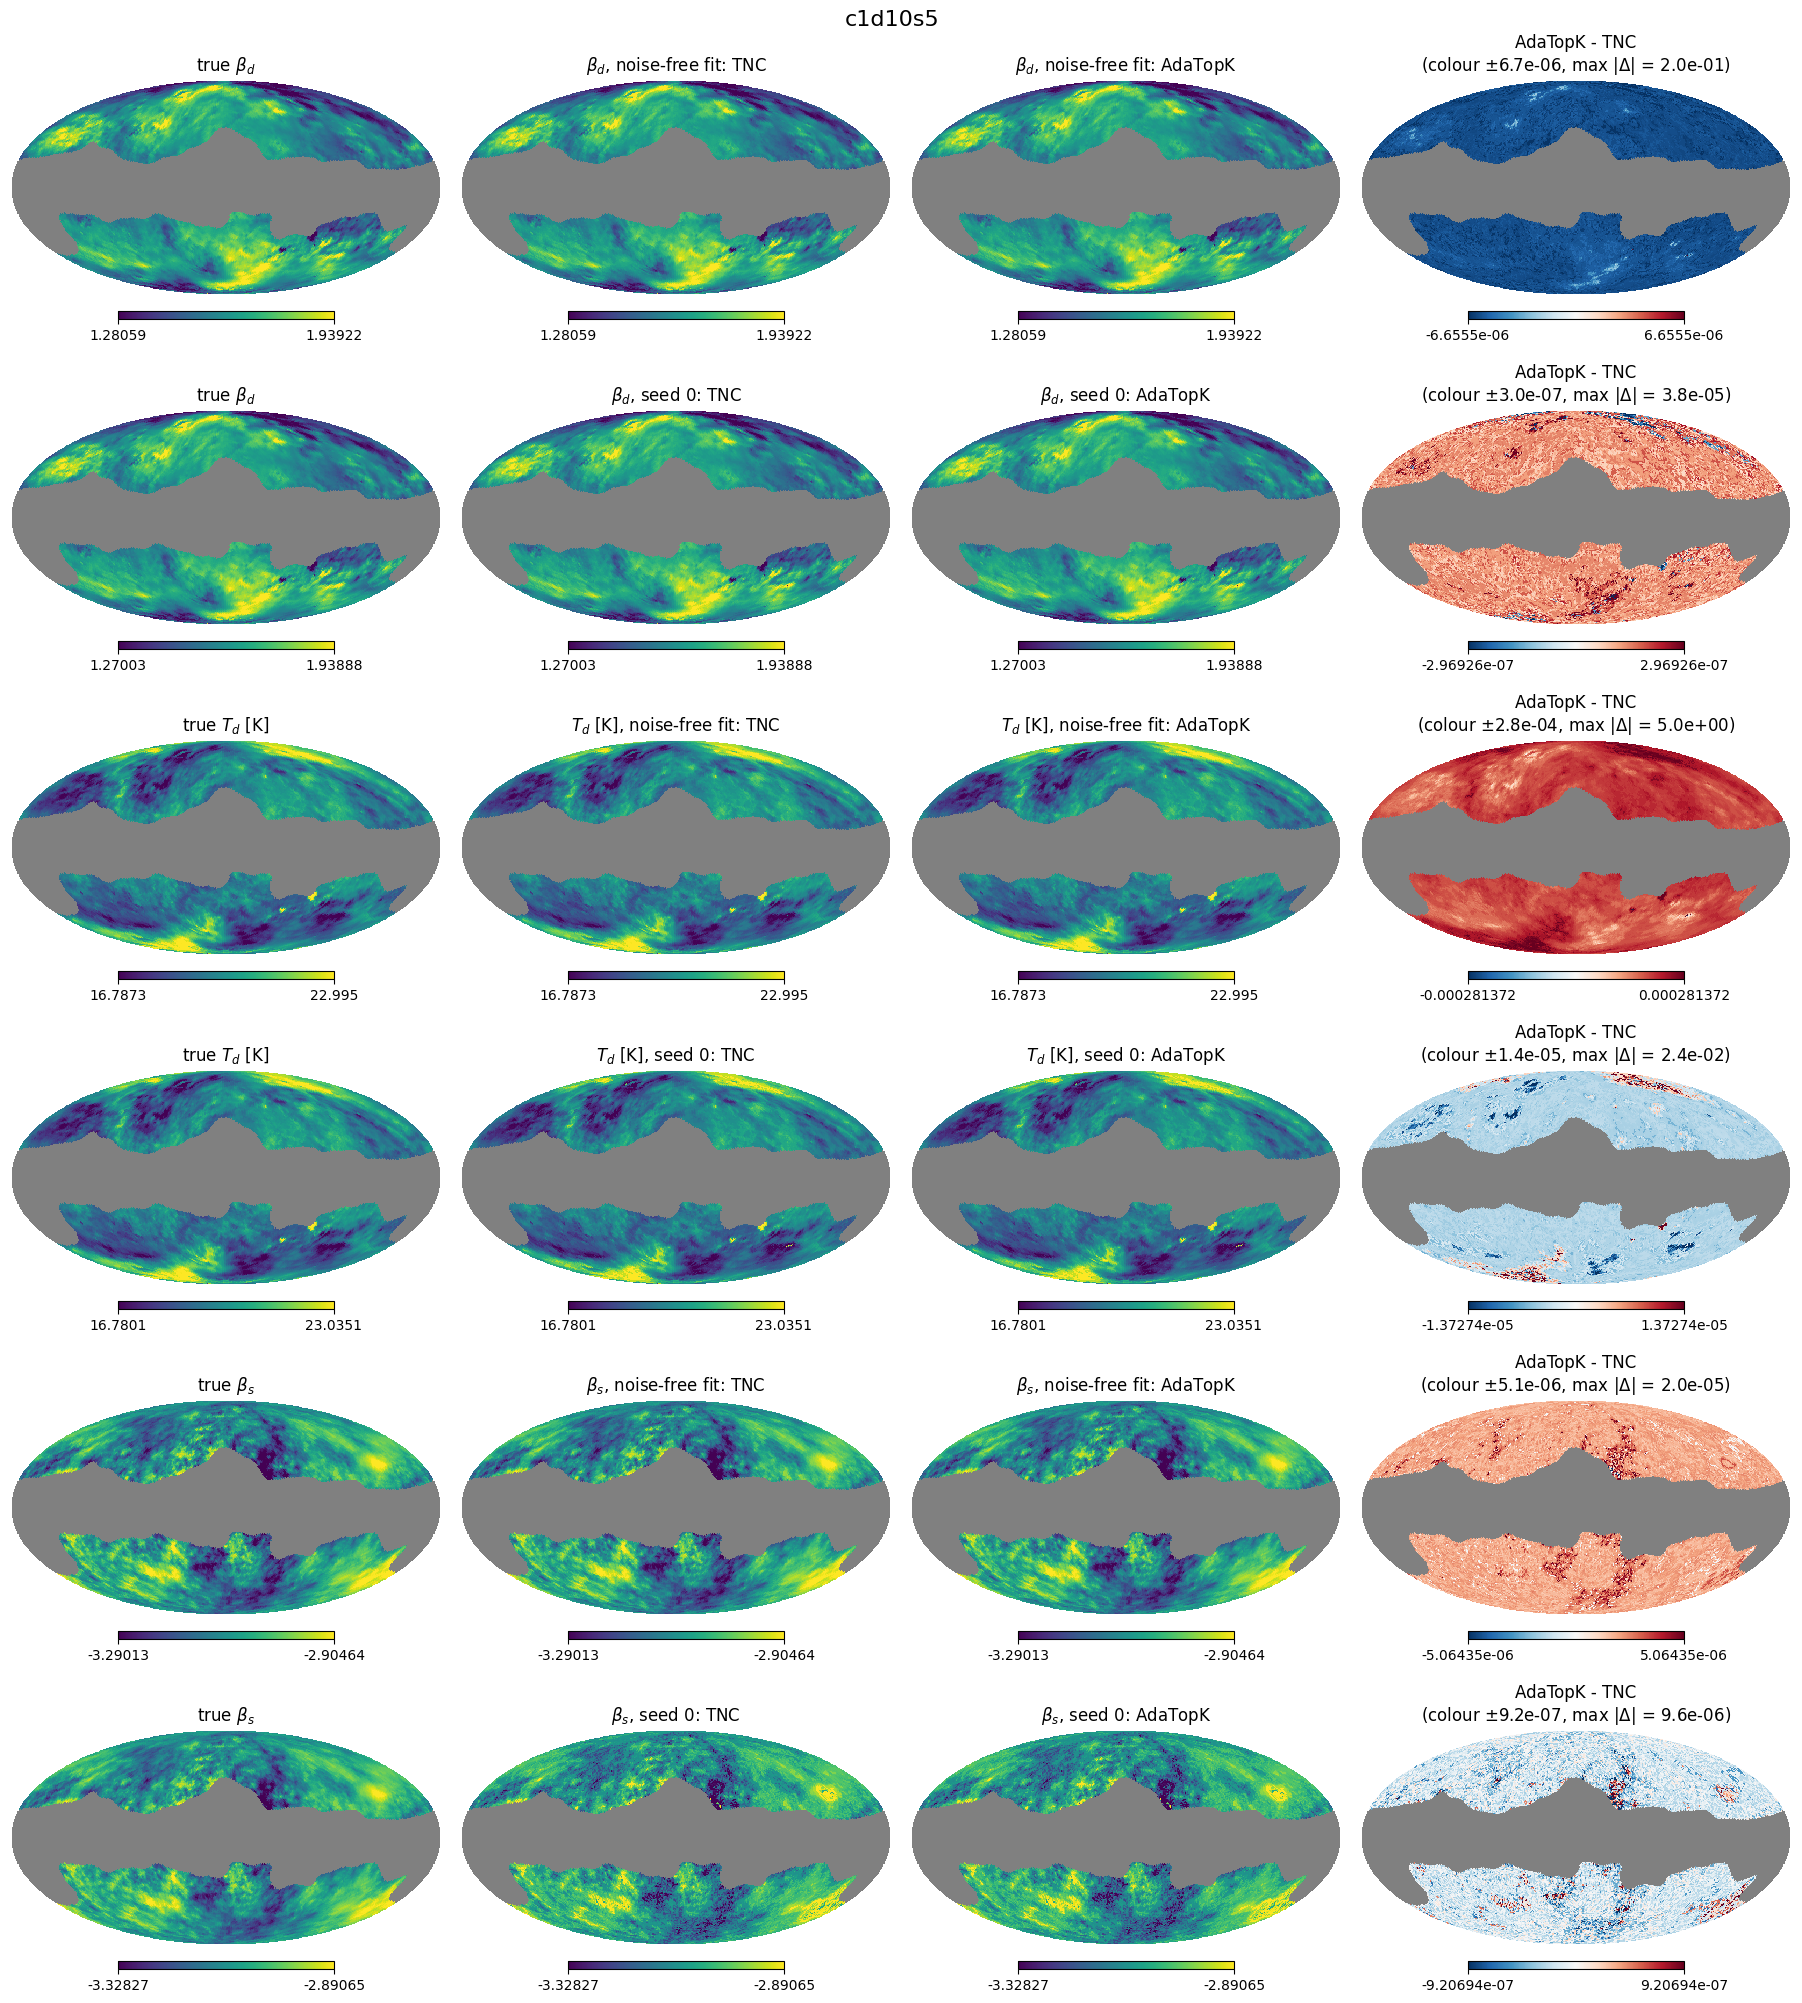

In [ ]:
plot_parameter_maps("c1d10s5")

## Tensor-to-scalar ratio

$\hat{r}$ and $\sigma(r)$ from the residual spectra, with `estimate_r` of `furax_cs.r_analysis`
($f_{\rm sky}$-corrected likelihood), on a grid of $\pm 10^{-3}$ (step $2 \times 10^{-6}$). The
input sky has $r = 0$.

In [ ]:
r_fits = {
    tag: {
        m: cm.r_estimate(skies[tag], spectra[tag][m]["cmb_hat"], spectra[tag][m]["wd"])
        for m in METHODS
    }
    for tag in SKIES
}
for tag in SKIES:
    for m, r in r_fits[tag].items():
        print(
            f"{tag} {m:7s}: r = {r['r_best']:.4e} (+{r['sigma_pos']:.3e} / -{r['sigma_neg']:.3e})"
        )

Computing Residual BB Spectra:   0%|          | 0/1 [00:00<?, ?it/s]

Computing Residual BB Spectra: 100%|██████████| 1/1 [00:00<00:00, 51.79it/s]

[INFO] Realization 0: min BB=3.15e-07, max BB=1.14e-06
Kept 1 out of 1 realizations after filtering.


Computing Residual BB Spectra:   0%|          | 0/1 [00:00<?, ?it/s]

Computing Residual BB Spectra: 100%|██████████| 1/1 [00:00<00:00, 26.02it/s]

[INFO] Realization 0: min BB=3.15e-07, max BB=1.14e-06
Kept 1 out of 1 realizations after filtering.


... (4 outputs left out)

Computing Residual BB Spectra:   0%|          | 0/1 [00:00<?, ?it/s]

Computing Residual BB Spectra: 100%|██████████| 1/1 [00:00<00:00, 48.30it/s]

[INFO] Realization 0: min BB=2.69e-07, max BB=9.11e-07
Kept 1 out of 1 realizations after filtering.


c1d1s1 TNC    : r = 1.0010e-06 (+8.609e-05 / -2.402e-05)
c1d1s1 AdaTopK: r = 1.0010e-06 (+8.609e-05 / -2.402e-05)
c1d10s5 TNC    : r = 7.0070e-06 (+8.609e-05 / -2.402e-05)
c1d10s5 AdaTopK: r = 7.0070e-06 (+8.609e-05 / -2.402e-05)


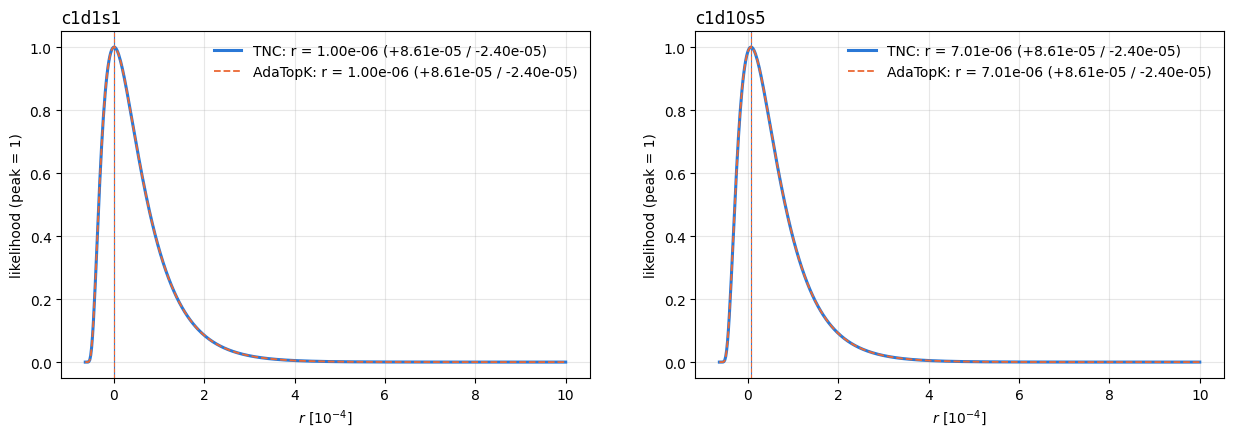

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, tag in zip(axes, SKIES):
    for m, ls, lw in (("TNC", "-", 2.2), ("AdaTopK", "--", 1.3)):
        r = r_fits[tag][m]
        ax.plot(
            r["r_grid"] * 1e4,
            r["likelihood"],
            color=COLORS[m],
            ls=ls,
            lw=lw,
            label=f"{m}: r = {r['r_best']:.2e} (+{r['sigma_pos']:.2e} / -{r['sigma_neg']:.2e})",
        )
        ax.axvline(r["r_best"] * 1e4, color=COLORS[m], ls=ls, lw=0.8)
    ax.set_title(tag, loc="left")
    ax.set_xlabel(r"$r$ [$10^{-4}$]")
    ax.set_ylabel("likelihood (peak = 1)")
    ax.legend(frameon=False, loc="upper right")
    ax.grid(alpha=0.3)
plt.show()